### We will solve $y''(x) = sin(x)$ with boundary condition y(0) = y(1) = 0. Analytical solution is given by $y(x) = x * sin(1) - sin(x)$.

1-norm of error: 6.4937e-06
2-norm of error: 3.2065e-07
Infinity-norm of error: 1.9998e-08


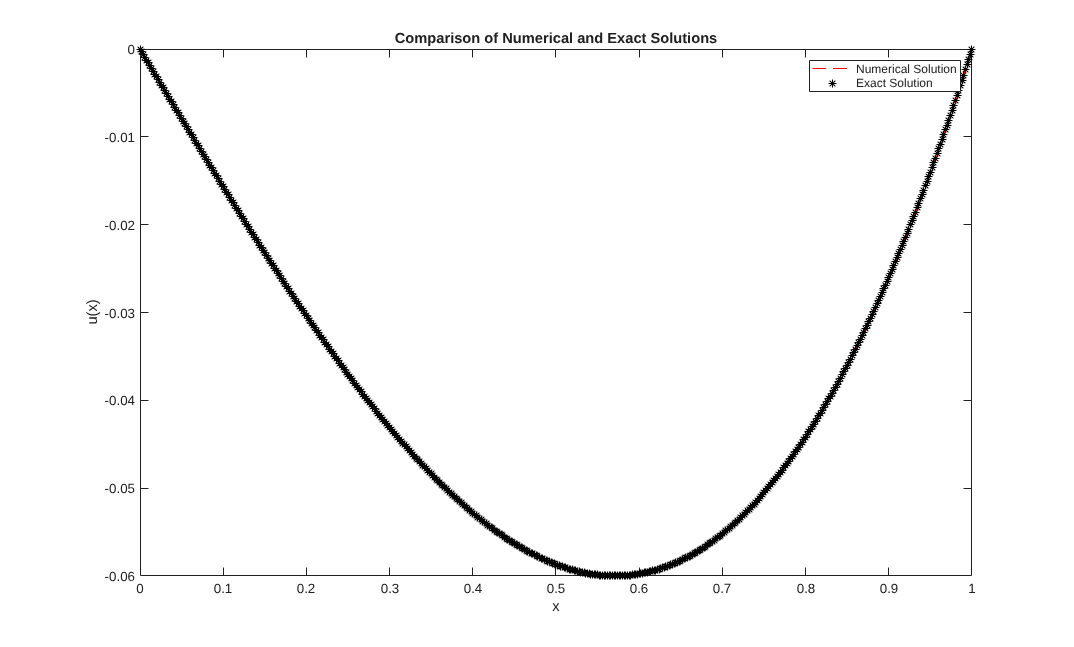

In [89]:
n = 500;
h = 1 / n;
x = linspace(0, 1, n+1);
point_count = n + 1;
A = diag(2*ones(n-1,1)) + diag(-1*ones(n-2,1),1) + diag(-1*ones(n-2,1),-1);
b = -h^2 * sin(x(2 : end - 1));
u = A \ b';
u = [0, u', 0];
plot(x, u, '--', 'Color', 'red');

u_exact = x * sin(1) - sin(x);
hold on;
plot(x, u_exact, '*', 'color', 'black');
legend('Numerical Solution', 'Exact Solution');
hold off;
xlabel('x');
ylabel('u(x)');
title('Comparison of Numerical and Exact Solutions');

disp("1-norm of error: " + norm(u - u_exact, 1))
disp("2-norm of error: " + norm(u - u_exact, 2))
disp("Infinity-norm of error: " + norm(u - u_exact, Inf))   

Solution didn't converge
Error norm (Gauss-Seidel) 1.582216e+01


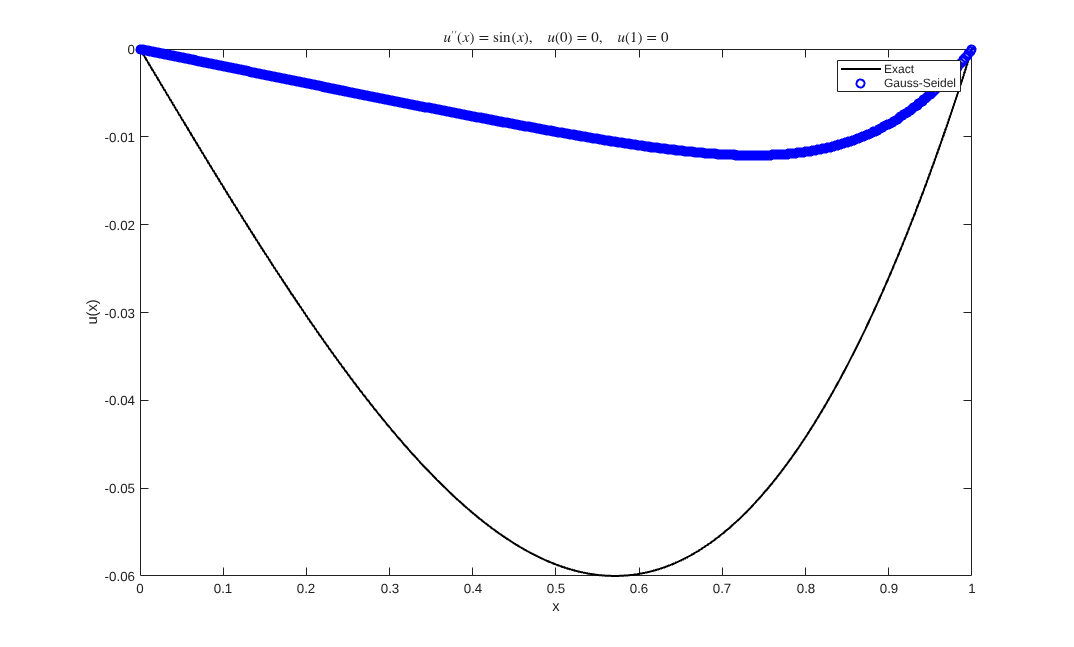

In [90]:
addpath('..');
% Now we try Gauss-Seidal method that I wrote in the parent directory
u_gauss_seidal = GaussSeidel(A, b, ones(point_count - 2, 1), 1e-6, 5000);
u_gauss_seidal = [0, u_gauss_seidal', 0];
error_norm_gauss_seidal = norm(u_gauss_seidal - u_exact, 1);
fprintf("Error norm (Gauss-Seidel) %e\n", error_norm_gauss_seidal);

% I would not use the SOR now 
% So we will just plot the exact solution and the Gauss-Seidel Solution on the same plot
plot(x, u_exact, 'k-', x, u_gauss_seidal, 'bo', 'LineWidth', 1.5);
legend('Exact', 'Gauss-Seidel');
xlabel('x');
ylabel('u(x)');
title('$$u^{\prime\prime}(x) = \sin(x), \quad u(0) = 0, \quad u(1) = 0$$');
set(get(gca, 'Title'), 'Interpreter', 'latex');



Solution didn't converge
Error norm (Jacobi) 4.046540e+02


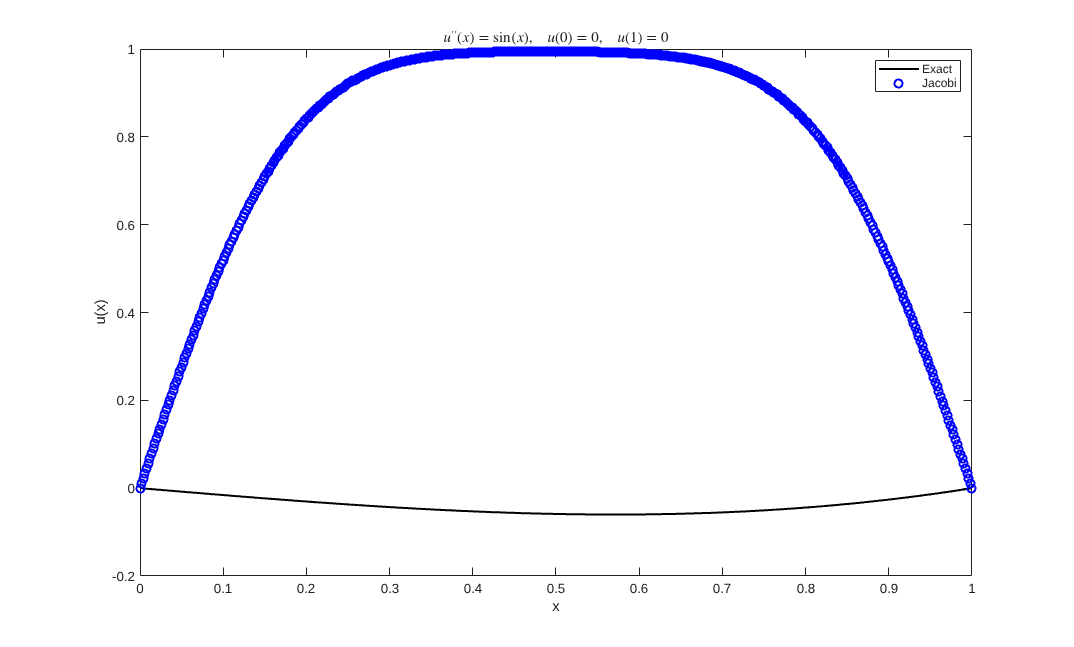

In [91]:
% Now we try the Jacobi Iteration
addpath('..');
% Now we try Gauss-Seidal method that I wrote in the parent directory
u_jacobi = JacobiIteration(A, b, ones(point_count - 2, 1), 1e-6, 5000);
u_jacobi = [0, u_jacobi', 0];
error_norm_jacobi = norm(u_jacobi - u_exact, 1);
fprintf("Error norm (Jacobi) %e\n", error_norm_jacobi);

% I would not use the SOR now 
% So we will just plot the exact solution and the Gauss-Seidel Solution on the same plot
plot(x, u_exact, 'k-', x, u_jacobi, 'bo', 'LineWidth', 1.5);
legend('Exact', 'Jacobi');
xlabel('x');
ylabel('u(x)');
title('$$u^{\prime\prime}(x) = \sin(x), \quad u(0) = 0, \quad u(1) = 0$$');
set(get(gca, 'Title'), 'Interpreter', 'latex');



Solution has converged.
    "Iteration Count: "    "1320"

Error norm (SOR) 1.281417e-03


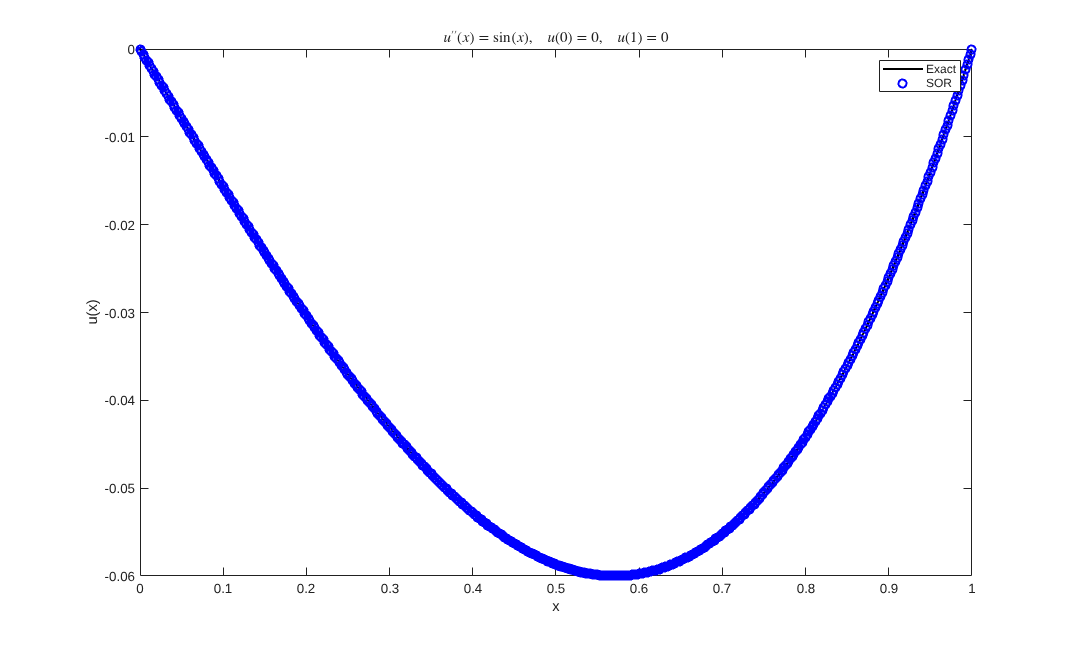

In [92]:
% Now we try the SOR method
%omega = 1.9; % Relaxation factor
omega = 2 / (1 + sin(pi/n));
%Sor_GaussSeidel(A, b, x0, tol, maxIter, w)
% Now we try the SOR Iteration
addpath('..');
u_SOR = Sor_GaussSeidel(A, b, ones(point_count - 2, 1), 1e-6, 5000, omega);
u_SOR = [0, u_SOR', 0];
error_norm_SOR = norm(u_SOR - u_exact, 1);
fprintf("Error norm (SOR) %e\n", error_norm_SOR);

% I would not use the SOR now 
% So we will just plot the exact solution and the Gauss-Seidel Solution on the same plot
plot(x, u_exact, 'k-', x, u_SOR, 'bo', 'LineWidth', 1.5);
legend('Exact', 'SOR');
xlabel('x');
ylabel('u(x)');
title('$$u^{\prime\prime}(x) = \sin(x), \quad u(0) = 0, \quad u(1) = 0$$');
set(get(gca, 'Title'), 'Interpreter', 'latex');




In [93]:
! cat -n ../GaussSeidel.m 

     1	function [x, counter] = GaussSeidel(A, b, x0, tol, maxIter)
     2	% This function performs Gauss-Seidel iteration to get the solution 
     3	% of a system of equation. 
     4	% Desired arguments: A, b, x0, tol, maxIter
     5	% Function signature ::
     6	% function [x, counter] = GaussSeidel(A, b, x0, tol, maxIter)
     7	
     8	%Step 1: perform the row swap to have maximum diagonal element 
     9	% as the pivot 
    10	b = b(:);
    11	Ab = [A, b];
    12	[m, n] = size(A);
    13	
    14	for i = 1 : m 
    15	
    16	    [~, maxIndex] = max(abs(Ab(i : end, i)));
    17	    k = i + maxIndex - 1;
    18	
    19	    if k ~= i 
    20	        Ab([i, k], :) = Ab([k, i], :);
    21	    end
    22	
    23	end
    24	
    25	A = Ab(:, 1 : end - 1);
    26	b = Ab(:, end);
    27	
    28	% step 2: design matrix C and column d 
    29	C = -A;
    30	d = zeros(m, 1);
    31	
    32	d = b;
    33	
    34	for i = 1 : n
    35	    C(i, i) = 0;
    36	    C(i, :) = C(i, :) / A(i, i);
  

In [94]:
! cat -n ../JacobiIteration.m

     1	function [x, count] = JacobiIteration(A, b, x0, tol, maxIter)
     2	% This function performs jacobi iteration to get the solution 
     3	% of a system of equation. 
     4	% Signature of the function
     5	% function [x, count] = JacobiIteration(A, b, x0, tol, maxIter)
     6	
     7	
     8	%Step 1: perform the row swap to have maximum diagonal element 
     9	% as the pivot 
    10	b = b(:);
    11	Ab = [A, b];
    12	[m, n] = size(A);
    13	
    14	for i = 1 : m 
    15	
    16	    [~, maxIndex] = max(abs(Ab(i : end, i)));
    17	    k = i + maxIndex - 1;
    18	
    19	    if k ~= i 
    20	        Ab([i, k], :) = Ab([k, i], :);
    21	    end
    22	
    23	end
    24	
    25	A = Ab(:, 1 : end - 1);
    26	b = Ab(:, end);
    27	
    28	% step 2: design matrix C and column d 
    29	C = -A;
    30	d = zeros(m, 1);
    31	
    32	d = b;
    33	
    34	for i = 1 : n
    35	    C(i, i) = 0;
    36	    C(i, :) = C(i, :) / A(i, i);
    37	    d(i) = d(i) / A(i, i);
    38	en

In [95]:
! cat -n ../Sor_GaussSeidel.m

     1	function [x, count] = Sor_GaussSeidel(A, b, x0, tol, maxIter, w)
     2	% This function performs Successive Over Relaxation on 
     3	% Gauss-Seidel iteration to get the solution 
     4	% of a system of equation. 
     5	% Desired arguments: A, b, x0, tol, maxIter, w
     6	% this function returns solution, count_iter
     7	
     8	%Step 1: perform the row swap to have maximum diagonal element 
     9	% as the pivot 
    10	b = b(:);
    11	Ab = [A, b];
    12	[m, n] = size(A);
    13	
    14	for i = 1 : m 
    15	
    16	    [~, maxIndex] = max(abs(Ab(i : end, i)));
    17	    k = i + maxIndex - 1;
    18	
    19	    if k ~= i 
    20	        Ab([i, k], :) = Ab([k, i], :);
    21	    end
    22	
    23	end
    24	
    25	A = Ab(:, 1 : end - 1);
    26	b = Ab(:, end);
    27	
    28	% step 2: design matrix C and column d 
    29	C = -A;
    30	d = zeros(m, 1);
    31	
    32	d = b;
    33	
    34	for i = 1 : n
    35	    C(i, i) = 0;
    36	    C(i, :) = C(i, :) / A(i, i);
  

Error norm (SOR) 3.817806e-02, Iterations 10000, omega 1.800000
Error norm (SOR) 3.449866e-02, Iterations 10000, omega 1.805000
Error norm (SOR) 3.100765e-02, Iterations 10000, omega 1.810000
Error norm (SOR) 2.770925e-02, Iterations 10000, omega 1.815000
Error norm (SOR) 2.460707e-02, Iterations 10000, omega 1.820000
Error norm (SOR) 2.170402e-02, Iterations 10000, omega 1.825000
Error norm (SOR) 1.900220e-02, Iterations 10000, omega 1.830000
Error norm (SOR) 1.650282e-02, Iterations 10000, omega 1.835000
Error norm (SOR) 1.420606e-02, Iterations 10000, omega 1.840000
Error norm (SOR) 1.211084e-02, Iterations 10000, omega 1.845000
Error norm (SOR) 1.021496e-02, Iterations 10000, omega 1.850000
Error norm (SOR) 8.514861e-03, Iterations 10000, omega 1.855000
Error norm (SOR) 7.005639e-03, Iterations 10000, omega 1.860000
Error norm (SOR) 5.680828e-03, Iterations 10000, omega 1.865000
Error norm (SOR) 4.532462e-03, Iterations 10000, omega 1.870000
Error norm (SOR) 3.551106e-03, Iteration

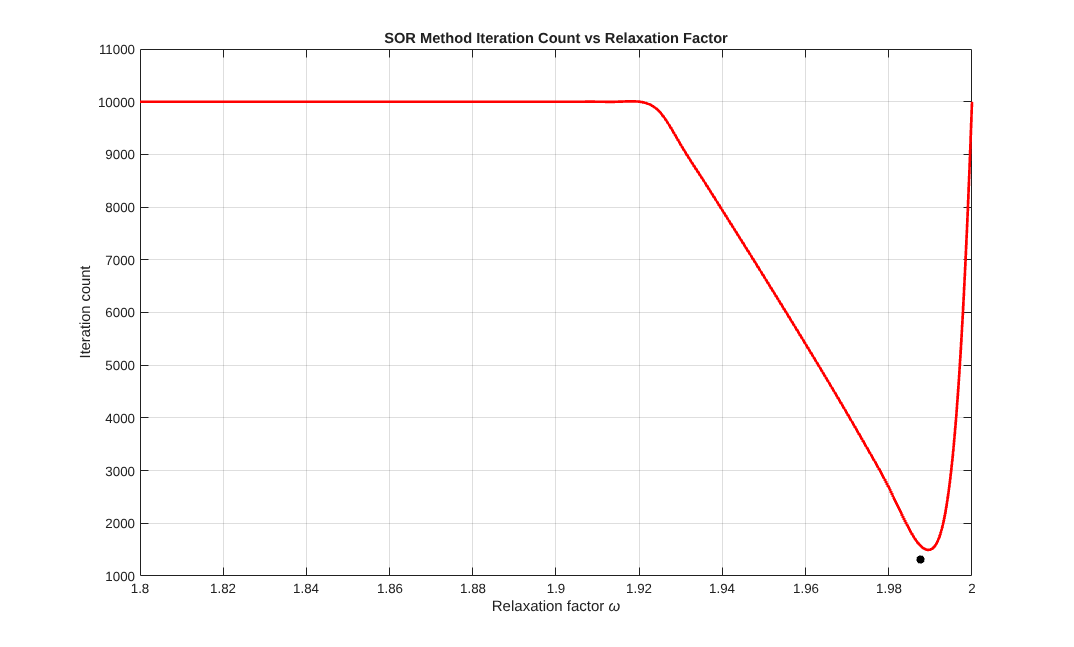

In [118]:
n = 500;
h = 1 / n;
x = linspace(0, 1, n+1);
point_count = n + 1;
A = diag(2*ones(n-1,1)) + diag(-1*ones(n-2,1),1) + diag(-1*ones(n-2,1),-1);
b = -h^2 * sin(x(2 : end - 1));
u = A \ b';
u = [0, u', 0];

% Now we try the SOR method varying the relaxation factor
omega_array = 1.8 : 0.005 : 2.0; % Array of relaxation factors to try
omega_best = 2 / (1 + sin(pi/n));
%Sor_GaussSeidel(A, b, x0, tol, maxIter, w)
% Now we try the SOR Iteration
addpath('..');
error_arr = zeros(1, length(omega_array));
iter_count_arr = zeros(1, length(omega_array));
for index = 1:length(omega_array)
    omega = omega_array(index);
    [u_SOR, iter_count] = Sor_GaussSeidel(A, b, ones(point_count - 2, 1), 1e-6, 10000, omega);
    u_SOR = [0, u_SOR', 0];
    error_norm_SOR = norm(u_SOR - u_exact, 'inf');
    error_arr(index) = error_norm_SOR;
    iter_count_arr(index) = iter_count;
    fprintf("Error norm (SOR) %e, Iterations %d, omega %f\n", error_norm_SOR, iter_count, omega);
end

[u_sor_opt, iter_count_opt] = Sor_GaussSeidel(A, b, ones(point_count - 2, 1), 1e-6, 10000, omega_best);
error_norm_sor_opt = norm([0, u_sor_opt', 0] - u_exact, 'inf');
fprintf("Error norm (SOR optimal) %e, Iterations %d, omega %f\n", error_norm_sor_opt, iter_count_opt, omega_best);
% Run cubic spline with the omega array for iteration count
omega_fine = linspace(min(omega_array), max(omega_array), 1000);
iter_count_fine = interp1(omega_array, iter_count_arr, omega_fine, 'spline');
plot(omega_fine, iter_count_fine, 'r', 'LineWidth', 2);
hold on;
xlabel('Relaxation factor \omega');
ylabel('Iteration count');
title('SOR Method Iteration Count vs Relaxation Factor');
grid on;

% let us plot the optimal omega point on the iteration count plot
plot(omega_best, iter_count_opt, 'k*', 'LineWidth', 2); % Highlight the optimal omega point
hold off;


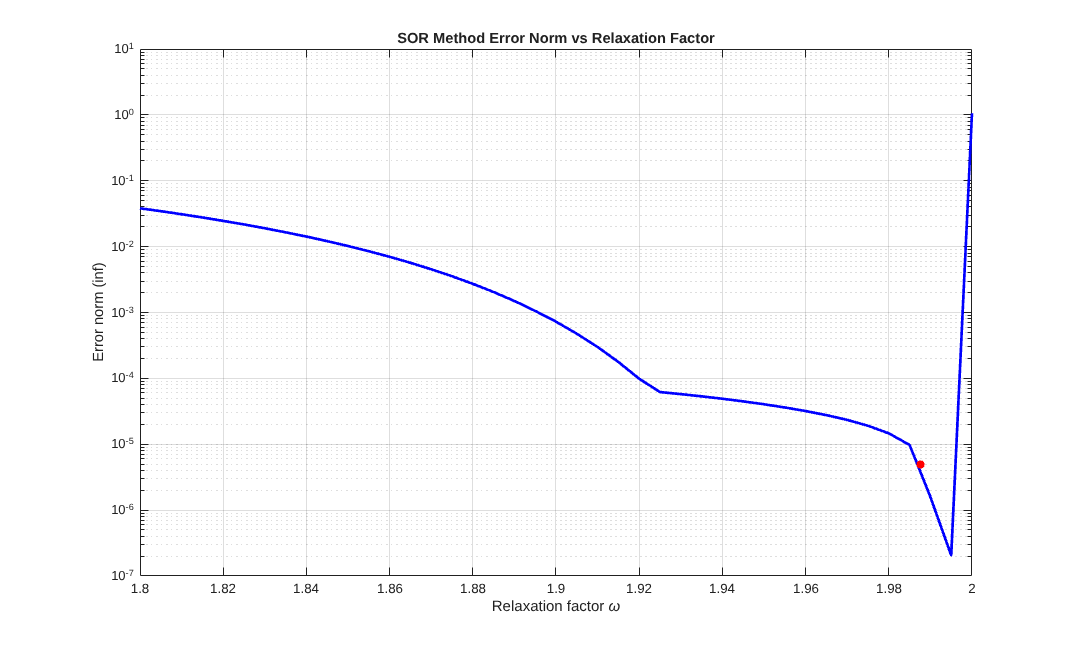

In [119]:
% let us do a plot with error norm versus relaxation factor
figure;
semilogy(omega_array, error_arr, 'b', 'LineWidth', 2);
hold on;
semilogy(omega_best, error_norm_sor_opt, 'r*', 'LineWidth', 2); % Highlight the optimal omega point
xlabel('Relaxation factor \omega');
ylabel('Error norm (inf)');
title('SOR Method Error Norm vs Relaxation Factor');
grid on;
hold off;

### Observation
Optimal omega performs better.